## D3 · Hypothesis testing

State hypotheses, calculate one- and two-tailed p-values, decide with a significance level, and see what Type I errors and power mean.

In [1116]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

from scipy.stats import norm

# Flipper lengths (mm) of Adelie penguins: the "typical Adelie penguin" that the hypotheses are about
df_complete = df_penguins.dropna()
col_adelie = df_complete.loc[df_complete["species"] == "Adelie", "flipper_length_mm"]

### Hypotheses and p-values

#### Null and alternative hypotheses

**D3.01**

`H0: x comes from N(mu, sd)   vs   H1: x is lower  or  x differs`

***(non-examinable)***

Writing down H₀ (the null hypothesis) and H₁ (the alternative) before looking at the result allows us to say exactly what a test is asking. The direction of H₁ decides whether a one-tailed or a two-tailed p-value is needed.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. The question throughout is whether a penguin with a flipper of 178 mm is a typical Adelie penguin.

A penguin with a 178 mm flipper is found. Is it a *typical Adelie penguin*? The null hypothesis says yes; the alternative says no, and there are two ways to say no: "shorter than typical" (one direction) or "different from typical" (either direction).

In [1117]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


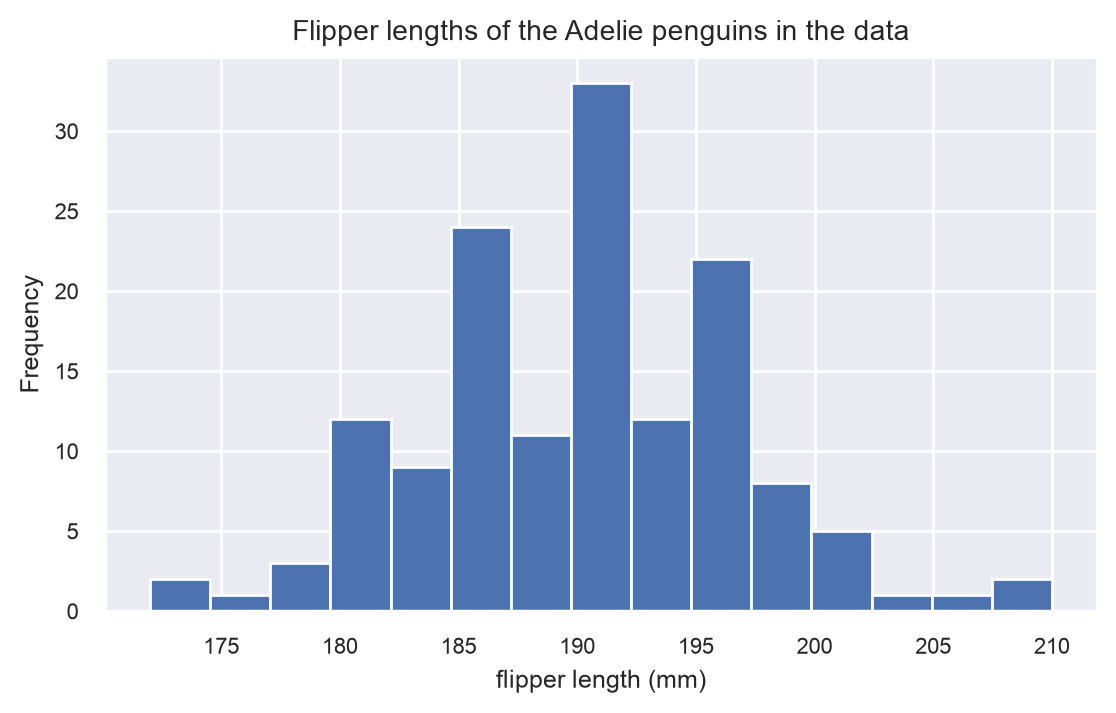

In [1118]:
col_adelie.plot.hist(bins=15, title="Flipper lengths of the Adelie penguins in the data")
plt.xlabel("flipper length (mm)");

In [1119]:
observed = 178
z = (observed - mu_a) / sd_a
print(f"H0: the penguin is a typical Adelie (mean {mu_a:.1f} mm, sd {sd_a:.1f} mm)")

H0: the penguin is a typical Adelie (mean 190.1 mm, sd 6.5 mm)


In [1120]:
print("H1 (one-sided): its flipper is shorter than a typical Adelie's")

H1 (one-sided): its flipper is shorter than a typical Adelie's


In [1121]:
print("H1 (two-sided): its flipper length differs from a typical Adelie's")

H1 (two-sided): its flipper length differs from a typical Adelie's


In [1122]:
print(f"observed {observed} mm is {z:.2f} standard deviations from the mean")

observed 178 mm is -1.86 standard deviations from the mean


Note: a one-sided H₁ is chosen only when two things hold, and both are decided **before** the data are seen. First, there is a reason why only one direction matters (here, for example, the penguin is suspected to be a young bird, which can only have a *shorter* flipper). Second, a result in the other direction would lead to the same conclusion as no difference. If either direction would be of interest, or if no direction was fixed in advance, the two-sided H₁ is the right one; it is also the default in most software and reports.

Note: these hypotheses are about **one observation** (is this penguin typical of the Adelie distribution?). A test about the **mean** of a group, as in the t-test sheet, states them with μ instead: H₀: μ = μ₀ against H₁: μ < μ₀ or μ ≠ μ₀.

Note: a confidence interval answers a similar question without stating hypotheses.

*See also:* One-tailed p-values (D3) · Two-tailed p-values (D3) · Z-scores (D2) · Choosing a t-test (D4)

#### One-tailed p-values

**D3.02**

`p = norm.cdf(observed, mu, sd)`

If we know the distribution of the measurement under H₀ (here a normal distribution), then the CDF at the observed value gives a one-tailed p-value: the probability of a result at least this extreme if H₀ is true. It is useful when H₁ was stated in one direction before the data were seen. Alternatively, use a two-tailed p-value when a difference in either direction would count as evidence, or when no direction was fixed in advance.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. The question throughout is whether a penguin with a flipper of 178 mm is a typical Adelie penguin.

In [1123]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1124]:
observed = 178
p_one = norm.cdf(observed, mu_a, sd_a)
print(f"observed flipper length: {observed} mm")

observed flipper length: 178 mm


In [1125]:
print(f"one-tailed p = {p_one:.4f}")

one-tailed p = 0.0317


Assumption: the calculation assumes that the flipper lengths are approximately normally distributed. A histogram with a normal curve (see the linked example) checks this.

Watch out: the tail is chosen from the question, not from the data. Looking at the observation first and then testing the tail it falls in doubles the chance of a false positive (from 5% to 10%), because a result in either direction can then be declared significant. The one-tailed p-value is also half the two-tailed one, so switching after the event makes the evidence look twice as strong as it is.

The shaded area under the curve is the p-value.

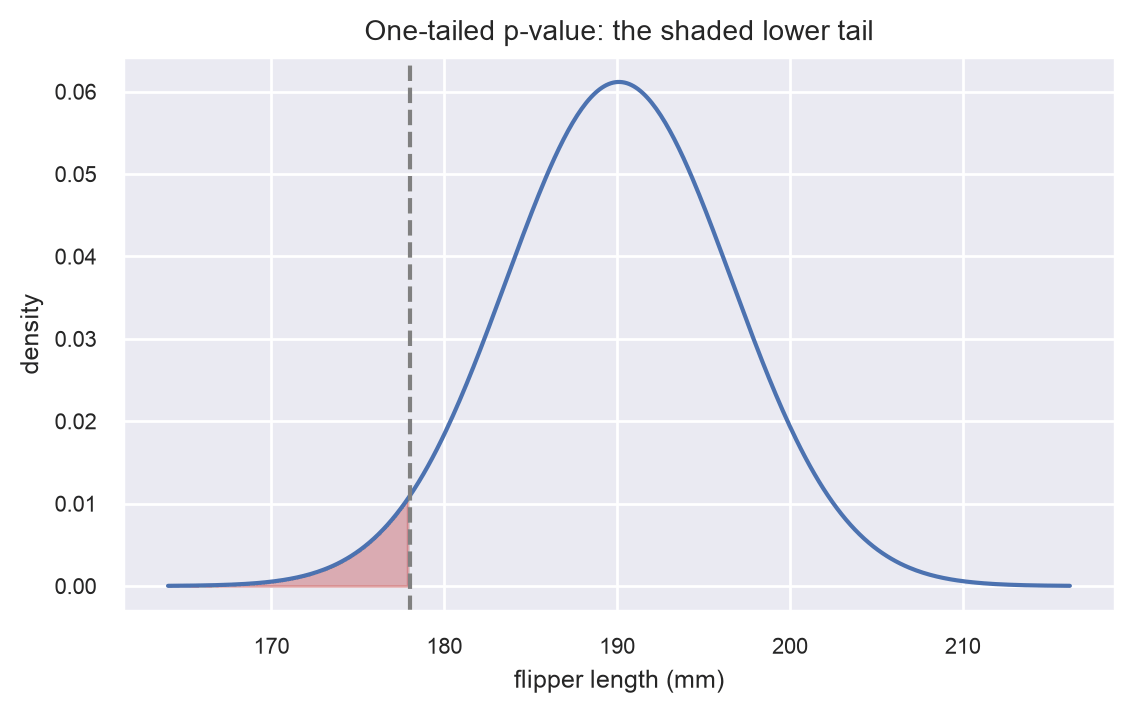

In [1126]:
x = np.linspace(mu_a - 4 * sd_a, mu_a + 4 * sd_a, 400)
y = norm.pdf(x, mu_a, sd_a)
plt.plot(x, y)
plt.fill_between(x, y, where=x <= observed, alpha=0.4, color="C3")
plt.axvline(observed, linestyle="--", color="grey")
plt.title("One-tailed p-value: the shaded lower tail")
plt.xlabel("flipper length (mm)")
plt.ylabel("density");

In [1127]:
print(f"If H₀ is true, the probability of a flipper length of {observed} mm or shorter is {p_one:.3f} ({p_one:.1%}). "
      + ("This is below 0.05, so a one-tailed test gives evidence that the penguin is shorter than a typical Adelie penguin."
         if p_one < 0.05 else "This is not below 0.05, so there is no evidence at the 5% level that the penguin is shorter than a typical Adelie penguin."))

If H₀ is true, the probability of a flipper length of 178 mm or shorter is 0.032 (3.2%). This is below 0.05, so a one-tailed test gives evidence that the penguin is shorter than a typical Adelie penguin.


*See also:* Two-tailed p-values (D3) · P(X ≤ x) with the CDF (D2) · Null and alternative hypotheses (D3) · Estimating a p-value by simulation (D3) · Comparing a histogram with a normal curve (D2) · Shading a tail of a distribution (D2)

#### Two-tailed p-values

**D3.03**

`norm.cdf(mu - diff, mu, sd) + (1 - norm.cdf(mu + diff, mu, sd))`

If either a very low or a very high value would count as evidence against H₀, then we add the probability in **both** tails to get a two-tailed p-value. It is useful when the alternative hypothesis is "different from", not "lower than". Alternatively, `2 * norm.cdf(-abs(z))` is the shortcut for a symmetric distribution.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. The question throughout is whether a penguin with a flipper of 178 mm is a typical Adelie penguin.

Assumptions: the flipper lengths are approximately normal, and the shortcut `2 * norm.cdf(-abs(z))` requires a symmetric distribution, which the normal distribution is.

In [1128]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1129]:
observed = 178
diff = abs(observed - mu_a)                      # distance from the mean
print(f"distance from the mean: {diff:.1f} mm")

distance from the mean: 12.1 mm


In [1130]:
p_two = norm.cdf(mu_a - diff, mu_a, sd_a) + (1 - norm.cdf(mu_a + diff, mu_a, sd_a))
print(f"two-tailed p = {p_two:.4f}")

two-tailed p = 0.0635


In [1131]:
print(f"shortcut     = {2 * norm.cdf(-abs((observed - mu_a) / sd_a)):.4f}")

shortcut     = 0.0635


In [1132]:
print(f"one-tailed p = {norm.cdf(observed, mu_a, sd_a):.4f}")

one-tailed p = 0.0317


Both shaded tails together make the p-value.

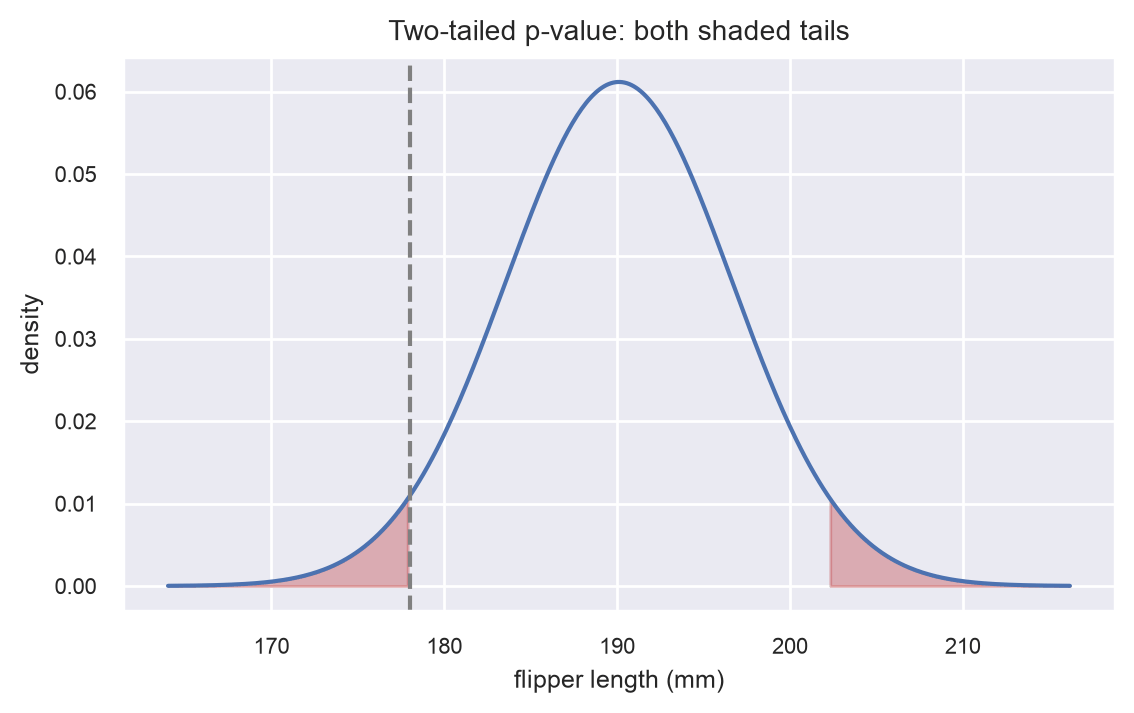

In [1133]:
x = np.linspace(mu_a - 4 * sd_a, mu_a + 4 * sd_a, 400)
y = norm.pdf(x, mu_a, sd_a)
d = abs(observed - mu_a)
plt.plot(x, y)
plt.fill_between(x, y, where=x <= mu_a - d, alpha=0.4, color="C3")
plt.fill_between(x, y, where=x >= mu_a + d, alpha=0.4, color="C3")
plt.axvline(observed, linestyle="--", color="grey")
plt.title("Two-tailed p-value: both shaded tails")
plt.xlabel("flipper length (mm)")
plt.ylabel("density");

In [1134]:
print(f"The two-tailed p-value is {p_two:.3f}, twice the one-tailed value, because the normal distribution is symmetric and a flipper equally far above the mean would also count as unusual. "
      + ("It is below 0.05, so the observation is evidence of a difference." if p_two < 0.05
         else "It is above 0.05, so the same observation gives weaker evidence when the alternative is \"different from\"."))

The two-tailed p-value is 0.063, twice the one-tailed value, because the normal distribution is symmetric and a flipper equally far above the mean would also count as unusual. It is above 0.05, so the same observation gives weaker evidence when the alternative is "different from".


*See also:* One-tailed p-values (D3) · Z-scores (D2) · Deciding whether to reject H0 (D3) · QQ plots (D4) · Comparing a histogram with a normal curve (D2)

#### Estimating a p-value by simulation

**D3.04**

`(simulated <= observed).mean()`

***(non-examinable)***

If we can draw random values from the null distribution, then the proportion of simulated values at least as extreme as the observation estimates the p-value, without any formula. It is useful for seeing what a p-value *means*, and when no formula exists. Alternatively, use `norm.cdf` for the exact value when the distribution is known.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. The question throughout is whether a penguin with a flipper of 178 mm is a typical Adelie penguin.

Assumption: the simulated values are drawn from a normal distribution with the sample mean and standard deviation, so the simulated p-value is only as good as that model.

In [1135]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1136]:
observed = 178
np.random.seed(1)                          # fixed seed, so the output is repeatable

In [1137]:
col_sim = norm.rvs(mu_a, sd_a, size=100_000)          # 100,000 "typical Adelie penguins" generated under H0
col_sim[:5].round(0)

array([201., 186., 187., 183., 196.])

Comparing every simulated value with the observation gives `True` where it is at least as short and `False` elsewhere. `True` counts as 1 and `False` as 0, so the **mean** of these values is the proportion of simulated values that are at least as short as the observation. This proportion is the estimated p-value:

In [1138]:
p_sim = (col_sim <= observed).mean()
print(f"simulated p = {p_sim:.4f}")

simulated p = 0.0312


In [1139]:
p_exact = norm.cdf(observed, mu_a, sd_a)                # the exact answer, for comparison
print(f"exact p     = {p_exact:.4f}")

exact p     = 0.0317


In [1140]:
print(f"The simulated p-value ({p_sim:.4f}) differs from the exact value ({p_exact:.4f}) by {abs(p_sim - p_exact):.4f}, so the simulation estimates the p-value well.")

The simulated p-value (0.0312) differs from the exact value (0.0317) by 0.0005, so the simulation estimates the p-value well.


*See also:* One-tailed p-values (D3) · Simulating many draws and comparing with the theory (D1) · Random samples with `rvs` (D2) · Comparing a histogram with a normal curve (D2) · Drawing random integers (A4)

### Making a decision

#### Deciding whether to reject H0

**D3.05**

`if p < alpha: reject H0`

Comparing the p-value with a significance level α (often 0.05) allows us to decide whether the evidence is strong enough to reject H₀. It is useful as the final step of any test. Alternatively, report the exact p-value and let the reader judge.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. The question throughout is whether a penguin with a flipper of 178 mm is a typical Adelie penguin.

Note: the significance level α is chosen before the data are examined. The decision is valid only if the assumptions of the test hold.

In [1141]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1142]:
observed = 178
alpha = 0.05
p_two = 2 * norm.cdf(-abs((observed - mu_a) / sd_a))
print(f"p = {p_two:.4f}   alpha = {alpha}")
if p_two < alpha:
    print("Reject H0 at the 5% level")
else:
    print("Fail to reject H0")

p = 0.0635   alpha = 0.05
Fail to reject H0


In [1143]:
print(f"p = {p_two:.3f} is " + ("less" if p_two < alpha else "greater") + f" than α = {alpha}, so H₀ is "
      + ("rejected." if p_two < alpha else f"not rejected. The data do not show that a flipper of {observed} mm differs from a typical Adelie penguin at the 5% level; this does not prove that it is typical."))

p = 0.063 is greater than α = 0.05, so H₀ is not rejected. The data do not show that a flipper of 178 mm differs from a typical Adelie penguin at the 5% level; this does not prove that it is typical.


*See also:* One-tailed p-values (D3) · Two-tailed p-values (D3) · Choosing with `if` and `else` (A2) · Critical values (D3)

#### Critical values

**D3.06**

`norm.ppf(alpha / 2, mu, sd), norm.ppf(1 - alpha / 2, mu, sd)   one-sided: norm.ppf(alpha, mu, sd)`

***(non-examinable)***

If we choose a significance level, then `norm.ppf` gives the critical value: how far from the mean a result must be before we reject H₀. It is useful as an equivalent to the p-value decision (reject if the observation is beyond the critical value). Alternatively, compare the p-value with α.

**Context.** The data are the flipper lengths (mm) of Adelie penguins, one of the three penguin species in the dataset. The question throughout is whether a penguin with a flipper of 178 mm is a typical Adelie penguin.

Assumption: the critical values are those of a normal distribution with the sample mean and standard deviation, so they are reliable only if the flipper lengths are approximately normal.

In [1144]:
# mean and standard deviation of the flipper lengths (mm) of Adelie penguins
mu_a, sd_a = col_adelie.mean(), col_adelie.std()
print(f"Adelie penguins: mean = {mu_a:.1f} mm, sd = {sd_a:.1f} mm")

Adelie penguins: mean = 190.1 mm, sd = 6.5 mm


In [1145]:
observed = 178
alpha = 0.05
low, high = norm.ppf(alpha / 2, mu_a, sd_a), norm.ppf(1 - alpha / 2, mu_a, sd_a)
print(f"do not reject H0 for flipper lengths between {low:.1f} mm and {high:.1f} mm")

do not reject H0 for flipper lengths between 177.3 mm and 202.9 mm


In [1146]:
print(f"{observed} mm is inside that range: {low <= observed <= high}")

178 mm is inside that range: True


For a one-sided H₁ ("shorter than typical"), the whole 5% goes into the lower tail, so the cut-off is closer to the mean:

In [1147]:
low_one = norm.ppf(alpha, mu_a, sd_a)
print(f"one-sided: reject H0 for flipper lengths below {low_one:.1f} mm")

one-sided: reject H0 for flipper lengths below 179.4 mm


In [1148]:
print(f"{observed} mm is below it: {observed < low_one}")

178 mm is below it: True


The rejection regions are the two shaded tails, which together contain 5% of the distribution.

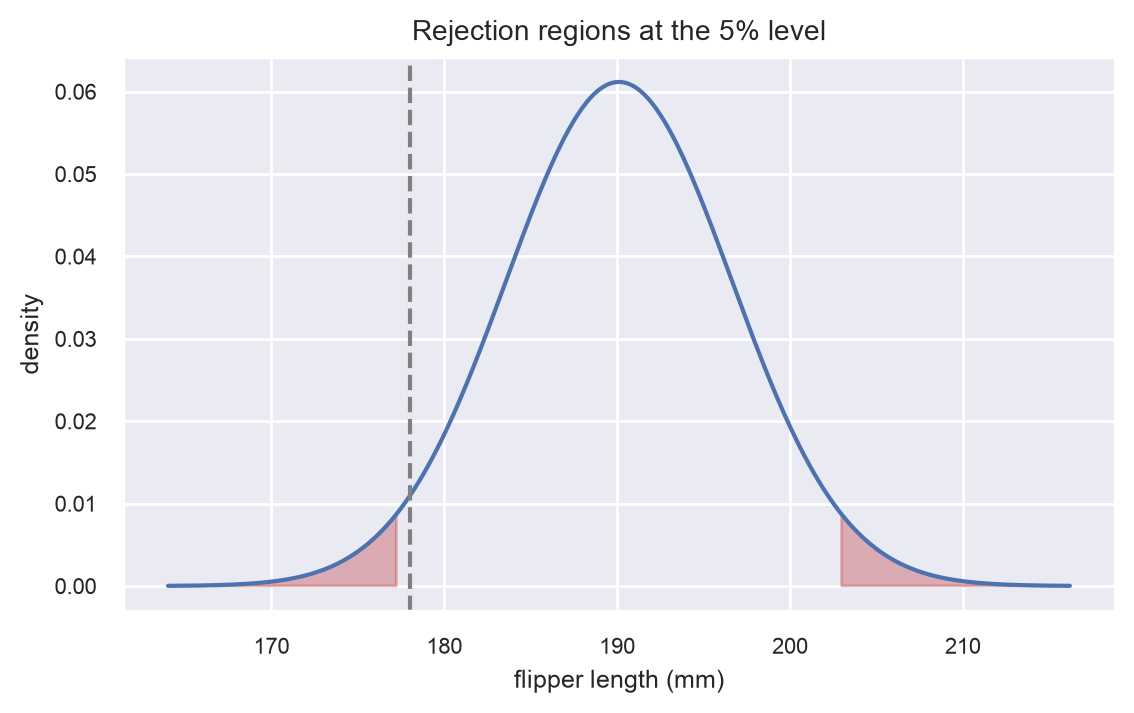

In [1149]:
x = np.linspace(mu_a - 4 * sd_a, mu_a + 4 * sd_a, 400)
y = norm.pdf(x, mu_a, sd_a)
plt.plot(x, y)
plt.fill_between(x, y, where=(x <= low) | (x >= high), alpha=0.4, color="C3")
plt.axvline(observed, linestyle="--", color="grey")
plt.title("Rejection regions at the 5% level")
plt.xlabel("flipper length (mm)")
plt.ylabel("density");

In [1150]:
inside = low <= observed <= high
print(f"At the 5% level, H₀ is rejected only for flipper lengths outside {low:.1f} to {high:.1f} mm. {observed} mm lies "
      + ("inside" if inside else "outside") + " this range, which agrees with the two-tailed p-value decision. "
      + f"With a one-sided H₁ (shorter than typical) the cut-off is {low_one:.1f} mm, and {observed} mm is " + ("below it, so H₀ would be rejected" if observed < low_one else "not below it, so H₀ would not be rejected")
      + ". The decision can depend on the choice of H₁, which is why it is fixed before the data are seen.")

At the 5% level, H₀ is rejected only for flipper lengths outside 177.3 to 202.9 mm. 178 mm lies inside this range, which agrees with the two-tailed p-value decision. With a one-sided H₁ (shorter than typical) the cut-off is 179.4 mm, and 178 mm is below it, so H₀ would be rejected. The decision can depend on the choice of H₁, which is why it is fixed before the data are seen.


*See also:* Percentiles with `ppf` (D2) · Deciding whether to reject H0 (D3) · Comparing a histogram with a normal curve (D2) · Critical t values (D4)

### Errors and power

#### False positives (type I error)

**D3.07**

`(p_values < 0.05).mean()`

***(non-examinable)***

Running many tests on data where H₀ is *true* allows us to see that about α of them still give p < α by chance (a Type I error). So a 5% significance level means that about 1 in 20 true nulls is "rejected", which is why many tests need adjusting.

**Context.** The data are simulated, so the truth is known: both groups are drawn from the same normal distribution (mean 100, standard deviation 5), with 20 values per group.

Note: the simulated data meet the assumptions of the t-test by construction (independent observations, normal distributions, equal variances). The observed rate therefore shows the ideal behaviour; with real data the rate can differ.
Both groups below come from the **same** distribution, so any "significant" difference is a false alarm. 2000 experiments are simulated, and a t-test is run on each one:

In [1151]:
rng = np.random.default_rng(1)
p_values = np.array([stats.ttest_ind(rng.normal(100, 5, 20), rng.normal(100, 5, 20)).pvalue
                     for _ in range(2000)])
len(p_values)                      # one p-value per experiment

2000

In [1152]:
p_values[:5].round(3)              # the first five p-values

array([0.819, 0.958, 0.614, 0.795, 0.539])

The question is: in what fraction of the experiments is the p-value below 0.05? This takes three small steps. First, comparing each p-value with 0.05 gives `True` (significant) or `False` (not significant) for every experiment:

In [1153]:
(p_values < 0.05)[:10]             # the first ten True/False results

array([False, False, False, False, False, False, False, False, False,
       False])

Second, Python treats `True` as 1 and `False` as 0, so the **sum** counts the significant experiments:

In [1154]:
(p_values < 0.05).sum()

np.int64(92)

Third, the **mean** of a set of 1s and 0s is the proportion of 1s, which is the fraction of experiments that were significant. This is close to 0.05, the significance level:

In [1155]:
(p_values < 0.05).mean()

np.float64(0.046)

In [1156]:
rate = (p_values < 0.05).mean()
print(f"When H₀ is true, {rate:.1%} of the {len(p_values)} experiments gave p < 0.05, close to the significance level of 5%. This is the Type I error rate.")

When H₀ is true, 4.6% of the 2000 experiments gave p < 0.05, close to the significance level of 5%. This is the Type I error rate.


*See also:* Independent (Welch) t-tests (D4) · Adjusting p-values for many tests (D4) · Missed effects (power) (D3)

#### Missed effects (power)

**D3.08**

`(p_values < 0.05).mean()`

***(non-examinable)***

Running many tests on data where H₀ is *false* allows us to see how often a real difference is detected; that proportion is the power, and the rest are Type II errors. Power is what a sample-size plan aims to raise.

**Context.** The data are simulated, so the truth is known: the second group has a true mean 5 units higher (105 against 100), the standard deviation is 5, and there are 20 values per group.

Note: the simulated data meet the assumptions of the t-test by construction (independent observations, normal distributions, equal variances). The power therefore shows the ideal case; with real data it can be lower.
Now the second group has a true mean 5 units higher than the first, with 20 per group. 2000 experiments are simulated and a t-test is run on each:

In [1157]:
rng = np.random.default_rng(1)
p_values = np.array([stats.ttest_ind(rng.normal(100, 5, 20), rng.normal(105, 5, 20)).pvalue
                     for _ in range(2000)])
p_values[:5].round(3)              # the first five p-values

array([0.004, 0.   , 0.   , 0.002, 0.024])

`p_values < 0.05` gives `True` where the real difference was detected and `False` where it was missed. The mean of these True/False values (1 and 0) is the proportion detected, which is the estimated **power**:

In [1158]:
(p_values < 0.05).mean()

np.float64(0.883)

The power changes with the number per group and with the size of the difference:

In [1159]:
for n, diff in ((20, 5), (10, 5), (20, 2)):
    rng = np.random.default_rng(1)                     # the same seed for each setting
    p_sim = [stats.ttest_ind(rng.normal(100, 5, n), rng.normal(100 + diff, 5, n)).pvalue for _ in range(2000)]
    print(f"{n} per group, difference {diff}: power = {(np.array(p_sim) < 0.05).mean():.2f}")

20 per group, difference 5: power = 0.88


10 per group, difference 5: power = 0.58


20 per group, difference 2: power = 0.23


In [1160]:
power = (p_values < 0.05).mean()
print(f"With a true difference of 5 units and 20 per group, {power:.1%} of the {len(p_values)} experiments detected it (the power). The other {1 - power:.1%} were missed effects (Type II errors).")

With a true difference of 5 units and 20 per group, 88.3% of the 2000 experiments detected it (the power). The other 11.7% were missed effects (Type II errors).


Note: `TTestIndPower` calculates power from a formula, without simulation.

*See also:* Power analysis (D4) · Cohen's d (D4) · False positives (type I error) (D3)